# Analisi concentrazione Ostreopsis ovata 
Ostreopsis Ovata è una microalga bentonica, rintracciabile prevalentemente nei mesi estivi

Le fioriture sono frequentemente correlate al superamento di determinate soglie termiche dell'acqua



I campionamenti effettuati si dividono tra misure effettuate nella zona di fondo e nella colonna d'acqua.
Dato che è una specie bentonica prediligerà substrati rigidi e acque profonde, quindi anche zone diverse della stessa costa presenteranno concentrazioni molto differenti. 

Analizziamone la concentrazione in diversi siti della provincia di Brindisi  per capire se le fioriture siano un fenomeno localizzato o se si disperda lungo l'intera costa.


## a) Serie temporale della concentrazione di Ostreopis ovata

Analizziamo come cambia la concentrazione dell'alga in ciascuna stazione negli anni


### Biovolume

Esprimiamo  la concentrazione dell'alga in funzione del **Biovolume ($\mu\text{m}^3/\text{L}$)**, ovvero lo spazio tridimensionale occupato dalle cellule nell'acqua

La conversione da cell/L a $\mu\text{m}^3/\text{L}$ avviene moltiplicando la concentrazione di cell/L per il **biovolume medio** della cell e per la **densità cellulare**

Dati della letturatura riportano il valore di biovolume medio della cellula di Ostreopsis ovata pari a  $V \approx 30.000 \ \mu\text{m}^3$

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
import numpy as np

path=r'C:\\Users\\sofia\\Università\\Tirocinio\\Dati ARPA\\Arpa_Puglia_dataset\\Dataset_Ostreopsis-Aliena_2014-2023.xlsx'
df_ost = pd.read_excel(path, header=2, sheet_name=1)


### Grafico a Istogrammi
Creiamo un istogramma per ogni anno e per ogni quota di campionamento, in modo da avere una semplice comprensione del dato 

Per farlo occorre utilizzare la funzione di *Seaborn* 

    sns.barplot


La **media aritmetica** normalizza l'indice annuale

    estimator=np.mean
    


    
Innanzitutto verifichiamo la regolarità annua delle rilevazioni:


In [18]:
#verifico il numero di campionamenti per ciascun anno per sito e quota 

#Creazione della colonna Anno per verificare quante misurazioni sono state fatte 
df_ost['ANNO']=df_ost['Data'].dt.year #.dt.year estrae l'anno dalla colonna 'Data' e lo assegna alla nuova colonna 'ANNO'

#groupby crea una tabella che raggruppa i dati per le colonne elencate e ne calcola il numero di misure di densità ['Densità].count()
    #unstack(level='ANNO') trasforma la colonna 'ANNO' in intestazioni di colonna separate per ciascun anno
conteggio_campioni= df_ost.groupby(['SITO', 'QUOTA', 'ANNO'])['Densità Ostreopsis ovata (cell/L)'].count().unstack(level='ANNO')

print("NUMERO DI CAMPIONAMENTI PER CIASCUN ANNO")
display(conteggio_campioni)


NUMERO DI CAMPIONAMENTI PER CIASCUN ANNO


ANNO                                                 2014  2015  2016  2017  \
SITO                                  QUOTA                                   
APANI LIDO S.VINCENZO (BR)            Acque colonna     8     8     8     8   
                                      Acque fondo       8     8     8     8   
LA FORCATELLA PRIMA CASA BIANCA (BR)  Acque colonna     8     8     8     8   
                                      Acque fondo       8     8     8     8   
TORRE CANNE DI FRONTE AL FARO (BR)    Acque colonna     8     8     8     8   
                                      Acque fondo       8     8     8     8   

ANNO                                                 2018  2019  2020  2021  \
SITO                                  QUOTA                                   
APANI LIDO S.VINCENZO (BR)            Acque colonna     8     8     8     8   
                                      Acque fondo       8     8     8     8   
LA FORCATELLA PRIMA CASA BIANCA (BR)  Acque colonna     8     8     8     8   
                                      Acque fondo       8     8     8     8   
TORRE CANNE DI FRONTE AL FARO (BR)    Acque colonna     8     8     8     8   
                                      Acque fondo       8     8     8     8   

ANNO                                                 2022  2023  
SITO                                  QUOTA                      
APANI LIDO S.VINCENZO (BR)            Acque colonna     8     8  
                                      Acque fondo       8     8  
LA FORCATELLA PRIMA CASA BIANCA (BR)  Acque colonna     8     8  
                                      Acque fondo       8     8  
TORRE CANNE DI FRONTE AL FARO (BR)    Acque colonna     8     8  
                                      Acque fondo       8     8

### Realizzazione del grafico

per realizzare un grafico con 3 sottografici (uno per ciascuna stazione) occorre utilizzare: 

1.  **ciclo for**       
in modo che filtri la tabella e generi 3 grafici in sequenza 

      for sito in siti: 
        plt.figure()
        ax=plt.gca()
        sns.lineplot()
        ..


2.  **"sintassi orientata agli oggetti"** (Object Oriented)* di *Matplotlib*

    fig, (ax1 ax2, ax3) = plt.subplots(1,3, figsize())
    
Così invece che creare 3 grafici separati eseguendo lo script 3 volte creo un'unica finestra/figura contenente 3 sotto grafici (ax1, ax2, ax3) affiancati 

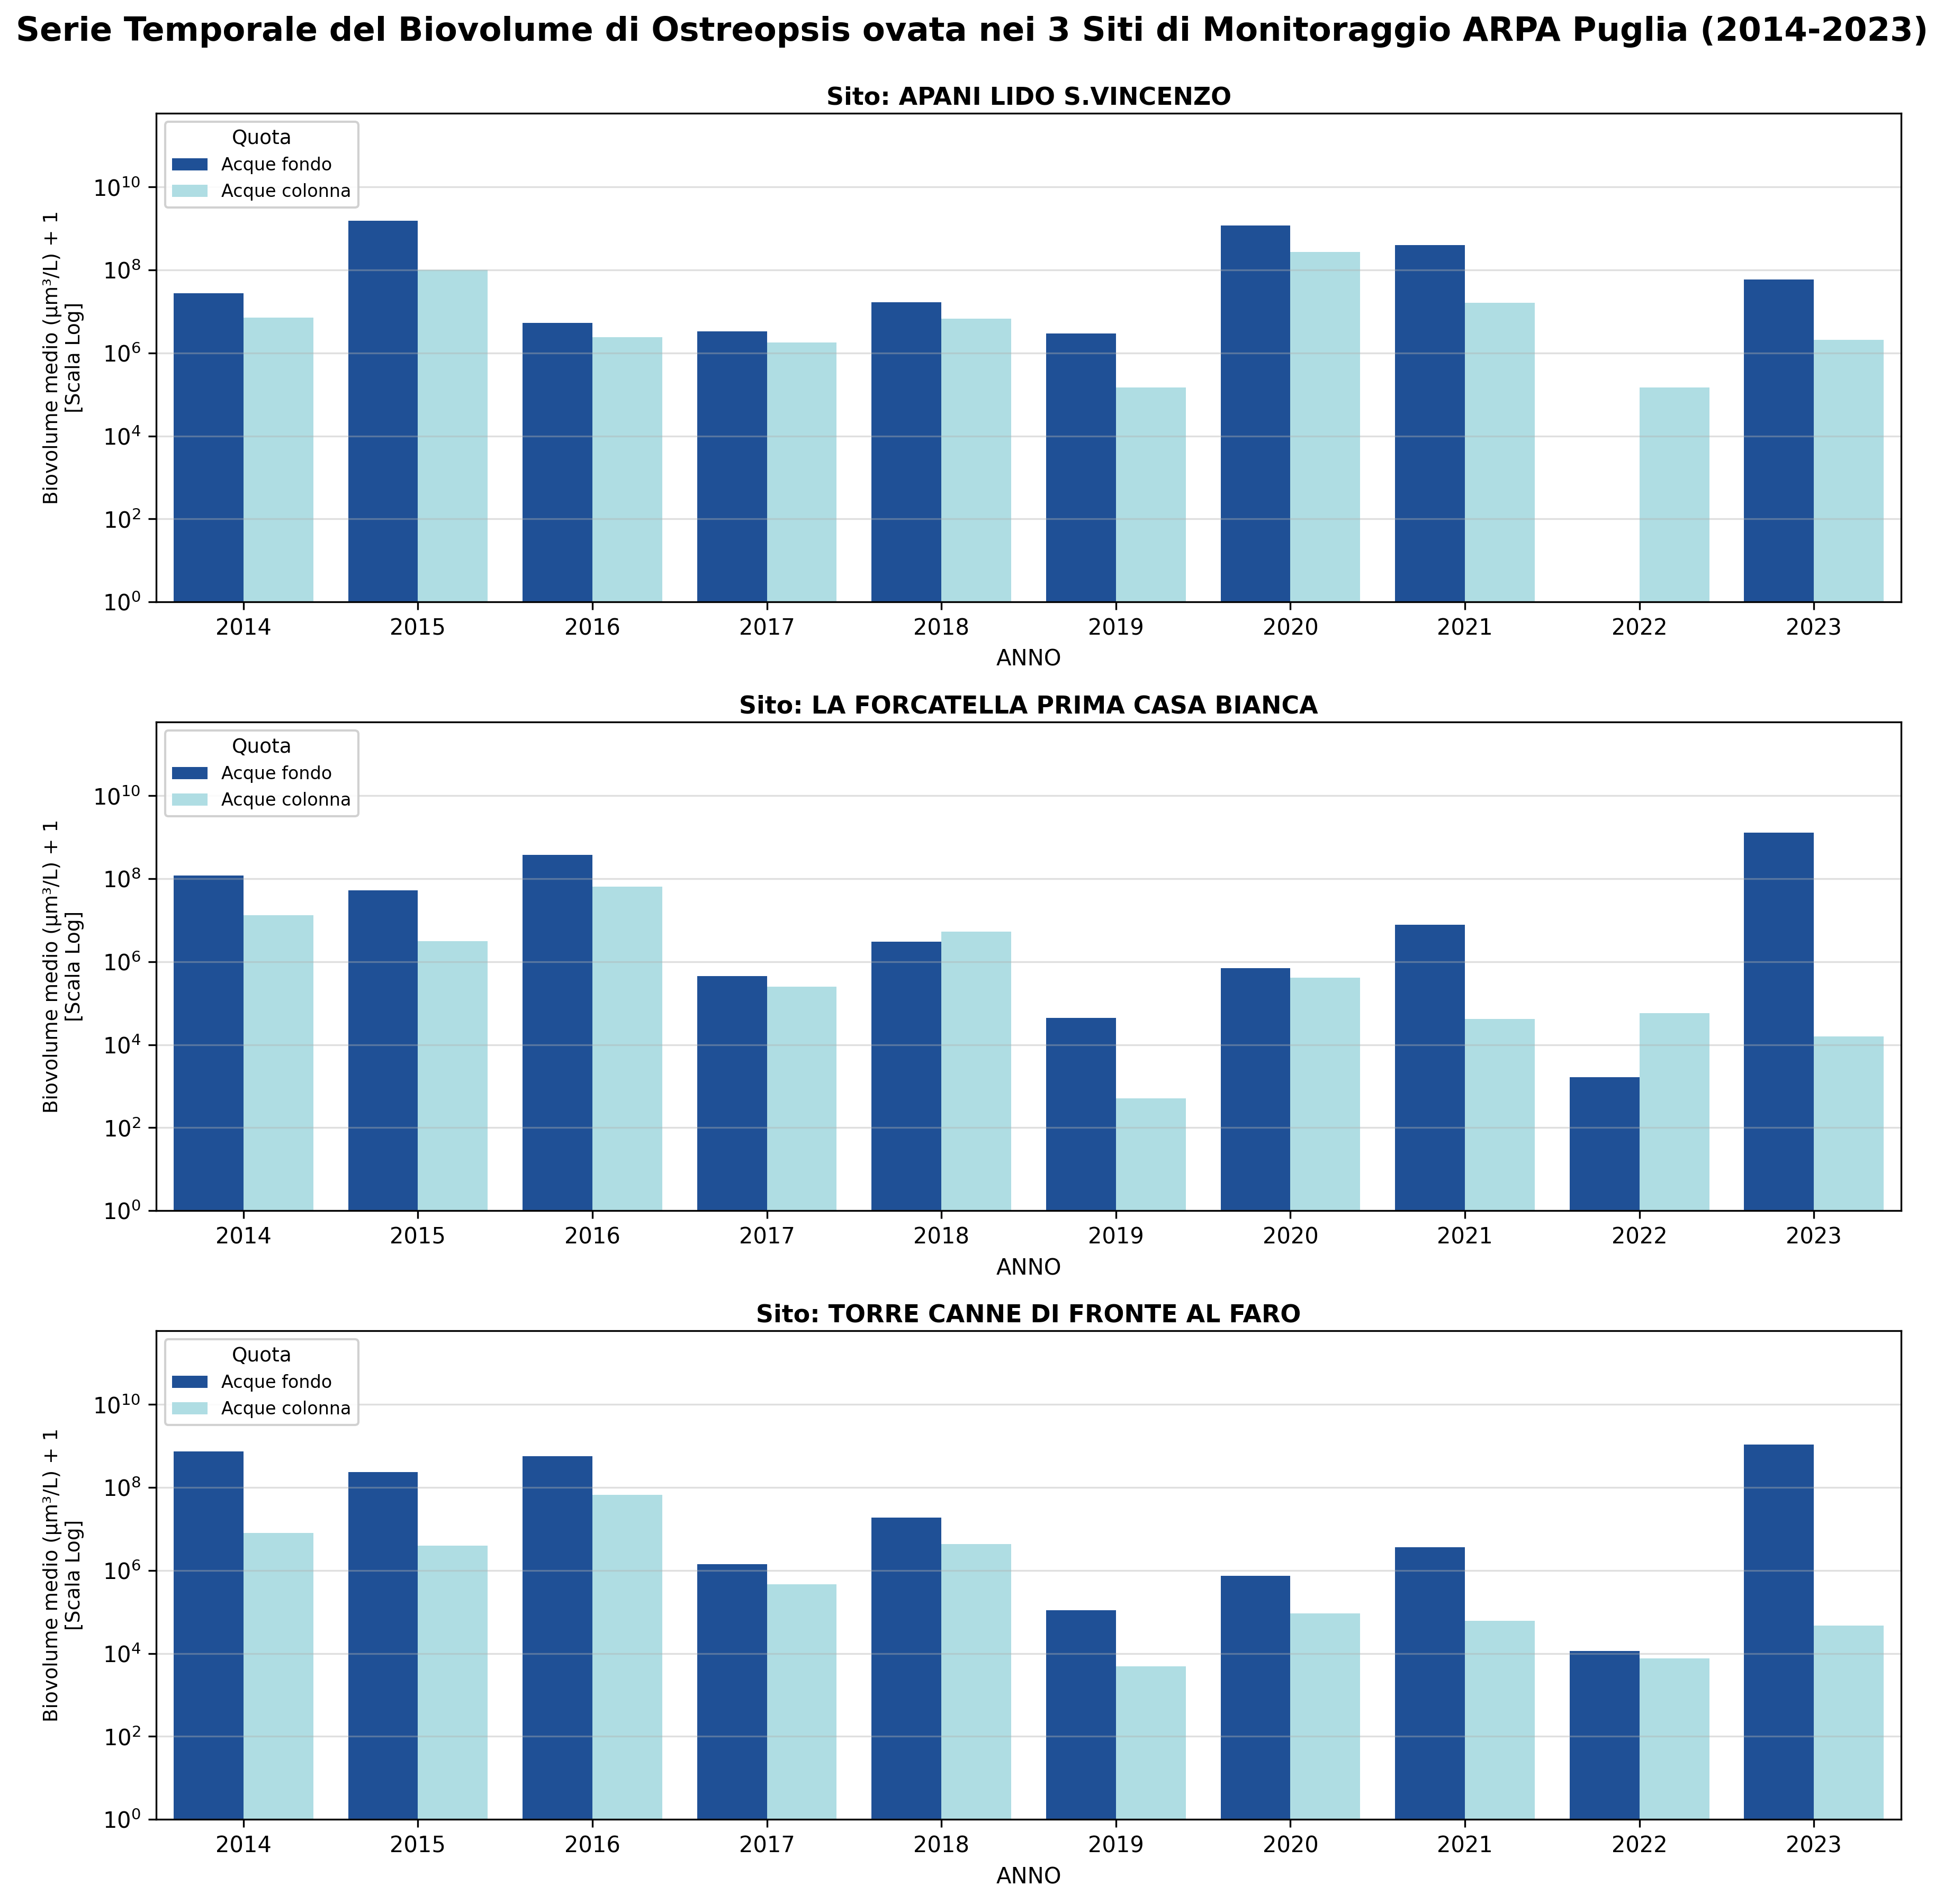

In [ ]:

# Caricamento del dataset Ostreopsis
df_ost['Data'] = pd.to_datetime(df_ost['Data'], format='%d/%m/%Y', errors='coerce')
df_ost['Densità'] = pd.to_numeric(df_ost['Densità Ostreopsis ovata (cell/L)'], errors='coerce').fillna(0)
df_ost['ANNO']=df_ost['Data'].dt.year
# Calcolo del Biovolume (30.000 um³ per cellula)
BIOVOLUME_CELLULA = 30000
df_ost['Biovolume_um3_L'] = df_ost['Densità'] * BIOVOLUME_CELLULA

# Data l'ampiezza dei valori del Biovolume, conviene utilizzare una scala logaritmica
# Ma dato che per Densità = 0 cell --> log0= indefinito
# ==> sommiamo +1 a tutti i valori (quantità trascurabile dato l'elevato numero di cellule). Così l'asse y parte da 1 (10^0) e non da 0 (10^-∞)
df_ost['Biovolume_um3_L'] = df_ost['Biovolume_um3_L'] + 1

# Lista dei 3 siti
siti = [
    'APANI LIDO S.VINCENZO (BR)', 
    'LA FORCATELLA PRIMA CASA BIANCA (BR)', 
    'TORRE CANNE DI FRONTE AL FARO (BR)'
]

palette = {'Acque fondo': '#0B4DAA', 'Acque colonna': "#A6E4EC"}

# Creazione del grafico 
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 12), dpi=300, sharey=True)    #sharey=True fa sì che tutti e 3 i grafici abbiano la stessa scala sull'asse y
assi = [ax1, ax2, ax3]

#il ciclo for scorre la lista dei siti e crea un grafico per ciascuno
for i, sito in enumerate(siti):    # i,sito = variabili a cui enumerate() associa rispettivamente l'indice e il valore nella lista 'siti'
    ax = assi[i]   #[i] prende l'asse corrispondente al sito corrente (ax1, ax2 o ax3)
    df_sito = df[df['SITO'].str.contains(sito, na=False, regex=False)].sort_values('Data')   #na=False non considera i NaN    #regex=False non considera punti, spazi come "caratteri speciali" 
        # .str.contains seleziona le righe in cui la colonna 'SITO' contiene il valore del sito corrente, .sortvalues le ordina per data

    # barplot disegna l'istogramma temporale per ciascun anno (vs mettendo x='data'creava un istogramma per ciascuna data)
    sns.barplot(
        data=df_sito,
        x='ANNO',
        y='Biovolume_um3_L',
        hue='QUOTA',
        palette=palette,
        estimator=np.mean,    #calcola la media del biovolume per quell'anno
        errorbar=None,  #disattiva le barre d'errore per un grafico + pulito
        ax=ax,
        dodge=True  # Affianca le barre di Fondo e Colonna se misurate lo stesso anno
    )
    
    # Scala logaritmica per gestire la forte variazione d'ordine di grandezza
    ax.set_yscale('log')
    ax.set_ylim(bottom=1, top=df['Biovolume_um3_L'].max() * 3)

    # griglia orizzontale
    ax.grid(True, which='major', linestyle='-', alpha=0.4, axis='y')
    ax.grid(True, which='minor', linestyle=':', alpha=0.2, axis='y')
    
    sito= sito.split(' (')[0]
    ax.set_title(f'Sito: {sito}', fontsize=11, fontweight='bold', pad=4)
    ax.set_ylabel('Biovolume medio (μm³/L) + 1\n[Scala Log]', fontsize=9)
    ax.legend(title='Quota', title_fontsize=9, fontsize=8, loc='upper left', frameon=True, facecolor='white', framealpha=0.9)

    #aggiungo i trattini in corrispondenza dei mesi sull'asse x



plt.suptitle('Serie Temporale del Biovolume di Ostreopsis ovata nei 3 Siti di Monitoraggio ARPA Puglia (2014-2023)', 
             fontsize=15, fontweight='bold', y=0.995)

plt.tight_layout()
plt.show()

## b) Correlazione con la variazione di Temperatura

Ora mettiamo in relazione la concentrazione di Ostreopsis ovata con la variazione di temperatura

Dato che le misure provengono da due reti di monitoraggio ARPA differenti con stazioni distinte, associamo ogni punto (*Ostreopis*) alla stazione di monitoraggio (Chimico - Fisico) geograficamente più vicina

Tramite una

    map ()
ovvero una sorta di "dizionario" per il codice possiamo associare le stazioni Ost a quella più vicina cis

    site_to_cis_map = {
    'APANI LIDO S.VINCENZO (BR)': 'MC_TG01',
    'TORRE CANNE DI FRONTE AL FARO (BR)': 'MC_VL01',
    'LA FORCATELLA PRIMA CASA BIANCA (BR)': 'MC_VL01',
    }
    
    df_ost['Codice_stazione'] = df_ost['Nome_stazione'].map(site_to_cis_map)
con il comando map abbiamo creato una nuova colonna nel df ostreopis in cui affianco al nome della stazione poniamo l'associazione precedente

Infine uniamo i dataframe tramite funzione di Pandas  

    pd.merge_asof(df1, df2, on='chiave unione', by=[condiz da rispettare], direction, tollerance)

questa funzione associa le righe in base alla chiave più vicina: ovvero la data SOLO SE i valori delle stazioni e della quota corrispondono (dividiamo le misure fatte a diverse profondità) 



In [12]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns


# Ricarichiamo il file Ost 
df_ost = pd.read_excel(r'C:\Users\sofia\Università\Tirocinio\Dati ARPA\Arpa_Puglia_dataset\Dataset_Ostreopsis-Aliena_2014-2023.xlsx', header=2, sheet_name=1)

# preparazione dei dati del df_ost
df_ost['Data'] = pd.to_datetime(df_ost['Data'], errors='coerce')
# .astype(str).str.strip() converte i valori della colonna in stringhe e rimuove eventuali spazi bianchi in modo da evitare errori di confronto causati da differenze di formattazione
df_ost['Nome_stazione'] = df_ost['SITO'].astype(str).str.strip()

df_ost['Densità Ostreopsis ovata (cell/L)'] = pd.to_numeric(df_ost['Densità Ostreopsis ovata (cell/L)'], errors='coerce')
Biovolume_cellulare = 30000
df_ost['Biovolume (um3/L)'] = df_ost['Densità Ostreopsis ovata (cell/L)'] * Biovolume_cellulare

# associamo ogni sito Ostreopsis al codice della stazione CIS più vicina 
site_to_cis_map = {
    'APANI LIDO S.VINCENZO (BR)': 'MC_TG01',
    'TORRE CANNE DI FRONTE AL FARO (BR)': 'MC_VL01',
    'LA FORCATELLA PRIMA CASA BIANCA (BR)': 'MC_VL01',
}
# Creiamo una nuova colonna 'Codice_stazione' nel dataframe df_ost che contiene il codice della stazione CIS corrispondente a ciascun sito Ostreopsis, utilizzando il mapping definito sopra
df_ost['Codice_stazione'] = df_ost['Nome_stazione'].map(site_to_cis_map)


# CARICHIAMO IL SECONDO FILE 
df_cis = pd.read_excel(r'C:\Users\sofia\Università\Tirocinio\Dati ARPA\Arpa_Puglia_dataset\Dataset_CIS-Aliena-2014-2023.xlsx', header=2, sheet_name=1)

# Rinominiamo le colonne per uniformarle a quelle del df_ost e rendere più chiaro il significato dei dati
df_cis = df_cis.rename(columns={'Codice Stazione': 'Codice_stazione', 'Quota prelievo': 'QUOTA'})
# Normalizziamo i nomi delle colonne per evitare errori dovuti a spazio/maiuscole
df_cis['Codice_stazione'] = df_cis['Codice_stazione'].astype(str).str.strip()
df_cis['QUOTA'] = df_cis['QUOTA'].astype(str).str.strip()
# preparazione dati di temperatura
df_cis['Data'] = pd.to_datetime(df_cis['Data'], errors='coerce')
df_cis['Temperatura (°C)'] = pd.to_numeric(df_cis['Temperatura (°C)'], errors='coerce')

#associamo le quote di campionamento del df_cis a quelle del df_ost per uniformare i nomi 
quota_map = {'FONDO': 'Acque fondo', 'SUPERFICIE': 'Acque colonna'}
df_cis['QUOTA'] = df_cis['QUOTA'].map(quota_map)

# selezioniamo solo le colonne di interesse nel df_cis e ne creiamo una copia + applichiamo dropna per evitare celle vuote/NaN  
    #la colonna 'Codice_stazione' serve per associare le stazioni del df_cis ai valori di temperatura corrispondenti, mentre la colonna 'QUOTA' associa le quote di campionamento del df_cis a quelle del df_ost
df_cis_clean = df_cis[['Data', 'Codice_stazione', 'QUOTA', 'Temperatura (°C)', ]].dropna(subset=['Data', 'Codice_stazione', 'QUOTA', 'Temperatura (°C)']).copy()

# ordiniamo per data (tramite .sort_values()) prima del merge (=unione)
df_cis_clean = df_cis_clean.sort_values('Data')
df_ost = df_ost.dropna(subset=['Data', 'Nome_stazione', 'Codice_stazione', 'QUOTA']).sort_values('Data')

# UNIONE --> tramite la funzione di pandas (pd) merge_asof()
    # gli argomenti iniziali sono i due df da unire
    # on='Data' indica che i due df devono essere uniti in base alla colonna 'Data'
    # by=['Codice_stazione', 'QUOTA'] indica che i due df devono essere uniti solo se i valori delle colonne 'Codice_stazione' e 'QUOTA' corrispondono
    # direction='nearest' indica che, se non c'è una corrispondenza esatta tra le date dei due df, la funzione prenderà la data più vicina (sia precedente che successiva) per fare il merge
    # tolerance=pd.Timedelta(days=15) indica la corrispondeza se non vi è esatta può essere presa in un intervallo max di 15 gg
df_unito = pd.merge_asof(
    df_ost,
    df_cis_clean,
    on='Data',
    by=['Codice_stazione', 'QUOTA'],
    direction='nearest',
    tolerance=pd.Timedelta(days=15)
)

# rimuoviamo le righe in cui la temperatura è NaN (cioè dove non c'è corrispondenza)
df_unito = df_unito.dropna(subset=['Temperatura (°C)']).copy()


# al df unito selezioniamo solo le colonne di interesse e ne creiamo una copia
df_final = df_unito[
    ['Data', 'Nome_stazione', 'Codice_stazione', 'QUOTA', 'Densità Ostreopsis ovata (cell/L)', 'Biovolume (um3/L)', 'Temperatura (°C)']
].copy()

print(f'Numero righe nel df: {len(df_final)}')

display(df_final)


Numero righe nel df: 196


,Data,Nome_stazione,Codice_stazione,QUOTA,Densità Ostreopsis ovata (cell/L),Biovolume (um3/L),Temperatura (°C)
0,2014-06-13,APANI LIDO S.VINCENZO (BR),MC_TG01,Acque fondo,500,15000000,22.12
1,2014-06-13,APANI LIDO S.VINCENZO (BR),MC_TG01,Acque colonna,320,9600000,22.66
6,2014-06-26,APANI LIDO S.VINCENZO (BR),MC_TG01,Acque fondo,200,6000000,22.12
7,2014-06-26,APANI LIDO S.VINCENZO (BR),MC_TG01,Acque colonna,120,3600000,22.66
44,2014-09-24,APANI LIDO S.VINCENZO (BR),MC_TG01,Acque colonna,120,3600000,21.85
...,...,...,...,...,...,...,...
463,2023-08-17,APANI LIDO S.VINCENZO (BR),MC_TG01,Acque colonna,0,0,27.67
464,2023-08-17,TORRE CANNE DI FRONTE AL FARO (BR),MC_VL01,Acque fondo,25358,760740000,27.45
465,2023-08-17,LA FORCATELLA PRIMA CASA BIANCA (BR),MC_VL01,Acque colonna,2802,84060000,27.52
466,2023-08-17,LA FORCATELLA PRIMA CASA BIANCA (BR),MC_VL01,Acque fondo,104432,3132960000,27.45


Ora l'obiettivo è convertire questa tabella in un grafico, ovvero mettendo in relazione le misure di temperatura con il Biovolume per vedere come cambia la concentrazione algale nelle 3 stazioni alle diverse quote col variare delle temperature

Creiamo il grafico in maniera analoga al precedente

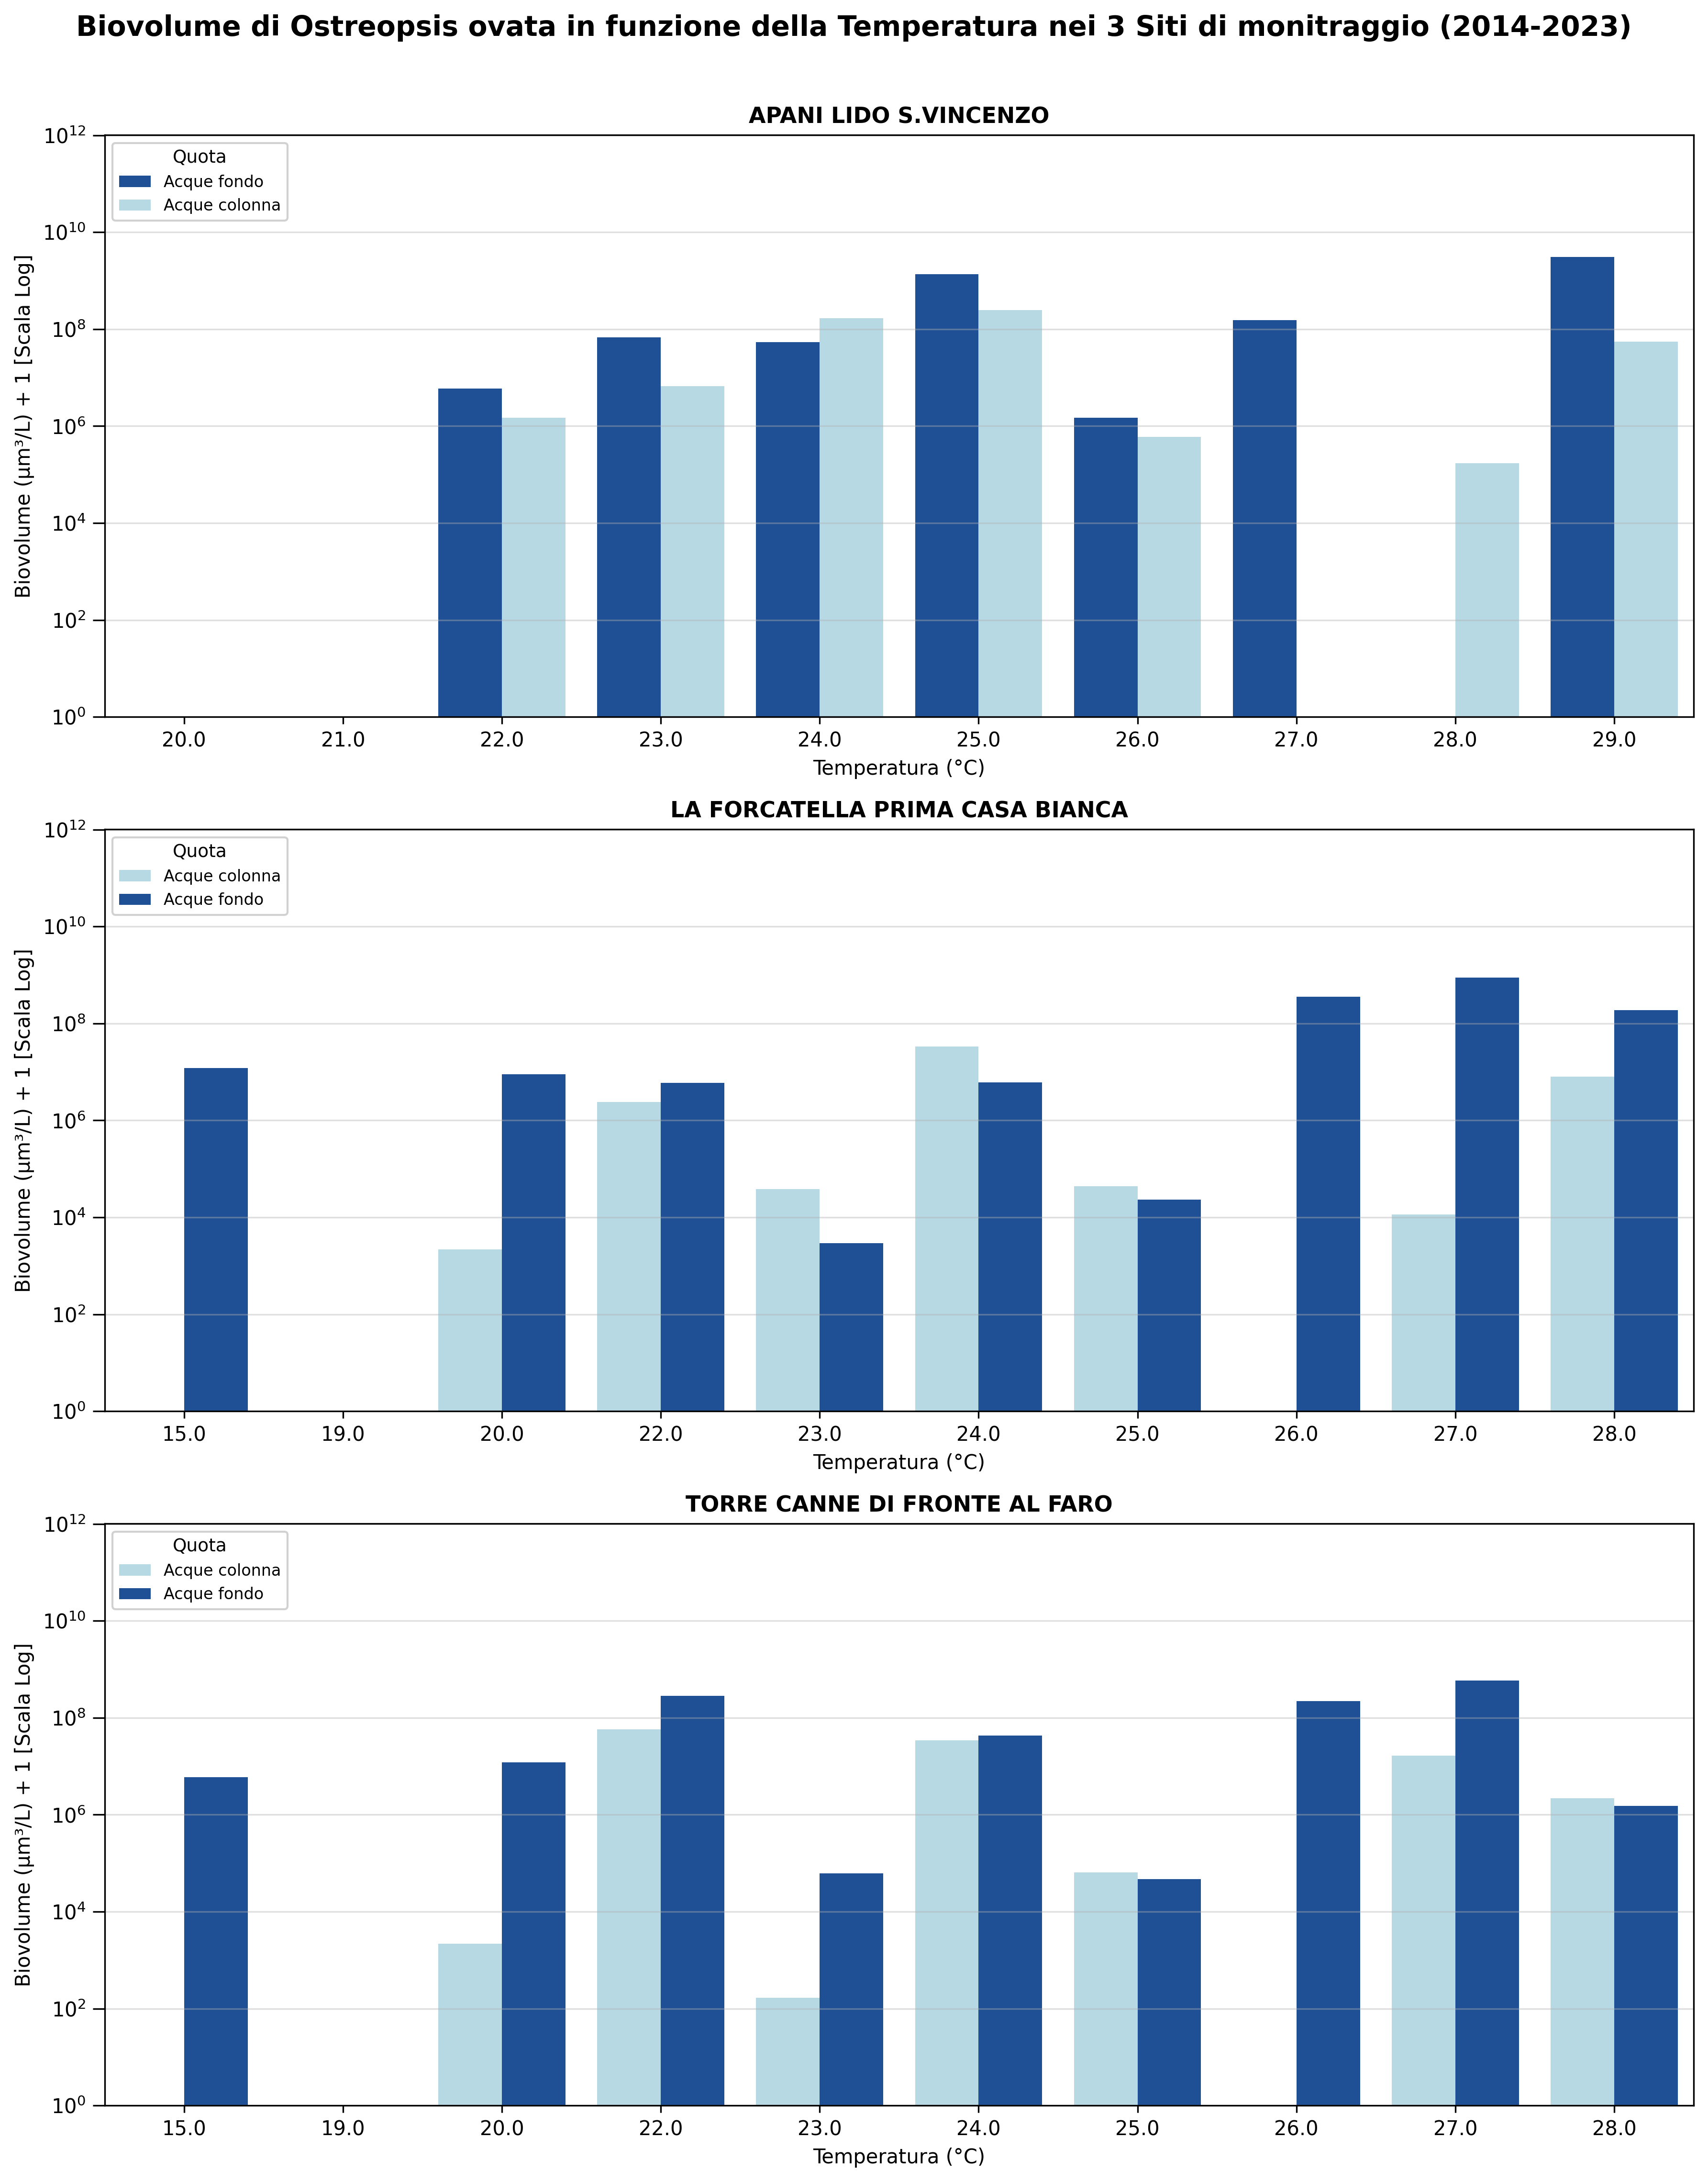

In [13]:
# Conversioni numeriche e gestione valori non validi
df_final['Temperatura (°C)'] = pd.to_numeric(df_final['Temperatura (°C)'], errors='coerce')
df_final['Biovolume (um3/L)'] = pd.to_numeric(df_final['Biovolume (um3/L)'], errors='coerce')

# Aggiungiamo +1 al biovolume per la scala logaritmica
df_final['Biovolume'] = df_final['Biovolume (um3/L)'].fillna(0) + 1

# Arrotondiamo la temperatura all'intero più vicino (°C) per creare classi omogenee nell'istogramma
df_final['Temp_Class'] = df_final['Temperatura (°C)'].round()

# Lista dei siti di monitoraggio
siti = ['APANI LIDO S.VINCENZO (BR)', 'LA FORCATELLA PRIMA CASA BIANCA (BR)', 'TORRE CANNE DI FRONTE AL FARO (BR)']

palette = {'Acque fondo': "#0B4DAA", 'Acque colonna': "#AEDDEC"}

# realizzazione dell'istogramma del biovolume in funzione della temperatura per ciascun sito
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 15), dpi=300, sharey=True)
assi = [ax1, ax2, ax3]
#max_biov definise il valore max per evitare sovrapoosizione dell'immagine con l'asse y 
max_biov = df_final['Biovolume'].max()

for i, sito in enumerate(siti):
    ax = assi[i]
    
    # Filtraggio dati per la stazione corrente
    df_sito = df_final[df_final['Nome_stazione'].str.contains(sito, na=False, regex=False)].dropna(subset=['Temp_Class'])
    df_sito = df_sito.sort_values('Temp_Class') # Ordina i dati per classe di temperatura
    #sns,barplot crea un istogramma con barre affiancate per le due quote di campionamento (FONDO e COLONNA) per ciascuna classe di temperatura
    sns.barplot(
        data=df_sito, #data seleziona il df da cui prendere dati
        x='Temp_Class', #asse x = classi di temperatura arrotondate all'intero più vicino
        y='Biovolume', 
        hue='QUOTA',
        palette=palette,
        errorbar=None,       # Disattiva le barre di errore se si desidera la media semplice
        estimator=np.mean,   # Media del biovolume per ciascuna classe di temperatura
        ax=ax,
        dodge=True          # Affianca le barre di Fondo e Colonna per la stessa temperatura
    )

    ax.set_yscale('log')
    ax.set_ylim(bottom=1, top=max_biov * 5)

    # Formattazione griglia e tick dell'asse Y
    ax.yaxis.set_major_locator(mticker.LogLocator(base=10.0))
    ax.yaxis.set_minor_locator(mticker.LogLocator(subs=range(2, 10)))
    ax.tick_params(axis='y', which='minor', length=3.5, width=0.5)
    ax.tick_params(axis='y', which='major', length=6, width=0.8)
    
    # Griglia orizzontale
    ax.grid(True, which='major', linestyle='-', alpha=0.4, axis='y')
    ax.grid(True, which='minor', linestyle=':', alpha=0.2, axis='y')

    # Titoli ed etichette
    nome = sito.split(' (')[0]
    ax.set_title(f'{nome}', fontsize=11, fontweight='bold', pad=6)
    ax.set_ylabel('Biovolume (μm³/L) + 1 [Scala Log]', fontsize=10)
    ax.set_xlabel('Temperatura (°C)', fontsize=10)
    ax.legend(title='Quota', title_fontsize=9, fontsize=8, loc='upper left', frameon=True, facecolor='white', framealpha=0.9)

# Titolo generale
plt.suptitle(
    'Biovolume di Ostreopsis ovata in funzione della Temperatura nei 3 Siti di monitraggio (2014-2023)', 
    fontsize=14, 
    fontweight='bold', 
    y=1.01
)

plt.tight_layout()
plt.show()

## Considerazioni 

Dai risultati ottenuti emerge un chiaro quadro in cui la microalga prolifera tra 20°C e i 28°C 

Vi è un picco anomalo a 15° nelle 2 stazioni vicine più a nord (?)
Blooms dovuto ad altre cause non  legate alla temperatura 
